#Taller Análisis Inferial de Datos
###Semana 6
###Jose Luis Florián Guardias
###Fundamentos para la IA
###Docente: Cesar Alfonso Bolado


## Introducción

Este portafolio recoge el trabajo de análisis inferencial de datos desarrollado para la semana 6 de Fundamentos para la IA. La idea es mostrar, de manera ordenada, todo el camino que se siguió desde que se tomó el dataset hasta que se llegó a una conclusión con base estadística, integrando lo visto en estadística básica y en visualización de datos.

El análisis inferencial es clave en la toma de decisiones porque permite ir más allá de lo que muestran los datos que se tienen a la mano: con una muestra es posible sacar conclusiones sobre una población más amplia, siempre que se validen ciertos supuestos antes de aplicar una prueba. Sin ese paso, cualquier conclusión que se saque de los datos corre el riesgo de ser errónea o de no poder generalizarse.

Para este trabajo se utilizó el *Boston Housing dataset*, un conjunto de datos ampliamente usado en el aprendizaje de estadística y machine learning, que reúne información sobre distintos barrios (suburbios) de la ciudad de Boston: características como la tasa de criminalidad, el número promedio de habitaciones por vivienda, la proximidad a zonas de empleo, la calidad educativa de la zona (relación alumno-profesor), entre otras variables, y el valor medio de las viviendas en cada zona. A partir de este dataset se plantea un problema que busca establecer si existe relación entre alguna de estas características del barrio y el valor de las viviendas, lo cual se detalla con sus respectivas hipótesis en el siguiente apartado.




## Paso 1 – Importación de librerías

Para este análisis inferencial se importan las librerías que permiten cubrir todo el flujo de trabajo: **pandas** y **numpy** para la carga, manipulación y cálculo numérico sobre el dataset; **matplotlib** y **seaborn** para construir las visualizaciones exigidas (histogramas, boxplots y scatter plots); y **scipy.stats**, que aporta las pruebas estadísticas necesarias para evaluar normalidad, homogeneidad de varianzas y el análisis inferencial que se seleccione más adelante (t-test, ANOVA, correlación, etc.).

Se configura además el estilo visual de *seaborn* y se ajusta pandas para mostrar todas las columnas del dataset sin truncar, de modo que la exploración inicial sea completa y legible.


In [ ]:
# PASO 1 – Importación de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración de visualización
sns.set(style="whitegrid")
pd.set_option('display.max_columns', None)

print("Librerías importadas correctamente")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Librerías importadas correctamente
pandas: 2.2.3
numpy: 2.1.3


## Paso 2 – Carga del dataset

En este paso se carga el archivo CSV del *Boston Housing dataset* en un DataFrame de pandas, con el fin de tener la información disponible para su exploración y posterior análisis. Se verifica la carga revisando la dimensión del conjunto de datos (número de filas y columnas) y una vista previa de los primeros registros.

Esta comprobación inicial es importante porque permite confirmar que el archivo se leyó correctamente antes de avanzar con el planteamiento del problema y el análisis estadístico.


In [ ]:
# PASO 2 – Carga del dataset

from google.colab import files

# Subir el archivo CSV descargado de Kaggle (Boston Housing dataset)
uploaded = files.upload()

# Leer el archivo (ajusta el nombre si Colab lo muestra distinto)
nombre_archivo = list(uploaded.keys())[0]
df = pd.read_csv(nombre_archivo)

# Verificación de la carga
print("Dimensiones del dataset (filas, columnas):", df.shape)
df.head()


Saving BostonHousing.csv to BostonHousing (1).csv
Dimensiones del dataset (filas, columnas): (506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


## Paso 3 – Comprensión del dataset

Antes de plantear el problema de análisis, es necesario entender la estructura del *Boston Housing dataset*: cuántas variables tiene, qué tipo de dato maneja cada una y si existen valores nulos que deban tratarse. El dataset cuenta con 506 registros y 14 variables, entre ellas: `crim` (tasa de criminalidad), `zn`, `indus`, `chas` (variable binaria de cercanía al río Charles), `nox` (contaminación), `rm` (número promedio de habitaciones), `age`, `dis`, `rad`, `tax`, `ptratio` (relación alumno-profesor), `b`, `lstat` (% de población de estatus bajo) y `medv` (valor medio de la vivienda en miles de USD), que será la variable de interés principal.

Esta exploración inicial permite identificar de una vez los tipos de dato de cada columna (todas numéricas en este caso) y confirmar la calidad de la información antes de definir la pregunta de investigación y las hipótesis.


In [ ]:
# PASO 3 – Comprensión del dataset

# Información general: tipos de dato y valores no nulos
df.info()

# Estadísticos descriptivos generales
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       501 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,501.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284341,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.705587,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.884000,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208000,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.625000,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [ ]:
# Verificación de valores nulos por columna
df.isnull().sum()

,0
crim,0
zn,0
indus,0
chas,0
nox,0
rm,5
age,0
dis,0
rad,0
tax,0


### Tratamiento de valores nulos

Al revisar la información general del dataset se identificaron 5 valores nulos en la variable `rm` (número promedio de habitaciones por vivienda), de un total de 506 registros. Dado que representan menos del 1% de los datos, se optó por imputar estos valores con la mediana de la variable, en lugar de eliminar los registros, para conservar el tamaño de muestra completo (n = 506) y no perder información de las demás columnas.

Se eligió la mediana y no la media porque es una medida más robusta ante posibles valores atípicos, y no afecta la interpretación general del análisis.


In [ ]:
# Tratamiento de valores nulos en 'rm'

mediana_rm = df['rm'].median()
df['rm'] = df['rm'].fillna(mediana_rm)

# Verificación final
print("Mediana usada para imputar 'rm':", mediana_rm)
print("Valores nulos restantes en el dataset:")
print(df.isnull().sum().sum())

Mediana usada para imputar 'rm': 6.208
Valores nulos restantes en el dataset:
0


## Paso 4 – Contexto del dataset y planteamiento del problema

El *Boston Housing dataset* representa información socioeconómica y ambiental de 506 zonas (suburbios) de la ciudad de Boston, recopilada para estudiar qué factores están asociados con el valor de las viviendas en cada zona. Cada registro incluye variables como la tasa de criminalidad, la contaminación ambiental, el número de habitaciones promedio, la calidad educativa de la zona y el valor medio de las viviendas (`medv`), entre otras.

El problema que se busca responder con inferencia estadística es si la cercanía de una zona al río Charles tiene relación con el valor de las viviendas en esa zona. Esto es relevante porque, si existiera una diferencia real, permitiría entender el río como un factor que agrega valor a la propiedad (por ejemplo, por vistas, recreación o prestigio), y no solo como una coincidencia de la muestra.

**Pregunta investigable:** ¿Existe una diferencia significativa en el valor promedio de las viviendas (`medv`) entre las zonas que limitan con el río Charles y las que no?

**Hipótesis:**
- **H0:** No existe diferencia significativa en el valor promedio de las viviendas entre las zonas que limitan con el río Charles y las que no limitan con él.
- **H1:** Existe una diferencia significativa en el valor promedio de las viviendas entre las zonas que limitan con el río Charles y las que no limitan con él.


In [ ]:
# PASO 4 – Verificación rápida de la variable independiente (chas)

print(df['chas'].value_counts())

chas
0    471
1     35
Name: count, dtype: int64


## Paso 5 – Identificación y clasificación de variables

Para este análisis se trabaja con dos variables del dataset:

- **Variable dependiente:** `medv` — variable **numérica continua** que representa el valor medio de las viviendas (en miles de USD) en cada zona. Es la variable de interés, sobre la cual se busca determinar si existe diferencia según el grupo.
- **Variable independiente:** `chas` — variable **categórica binaria** (dos grupos: 0 = la zona no limita con el río Charles, 1 = la zona sí limita con el río Charles). Es la variable que define los grupos a comparar.

Esta combinación (una variable numérica dependiente frente a una variable categórica de dos grupos) corresponde a un diseño de comparación de dos muestras independientes, en el que se evaluará más adelante si conviene aplicar una prueba paramétrica (t-test) o su alternativa no paramétrica (U de Mann-Whitney), según los supuestos de normalidad y homogeneidad de varianzas.

In [ ]:
# PASO 5 – Identificación y clasificación de variables

print("Variable dependiente: medv (numérica continua)")
print("Tipo de dato:", df['medv'].dtype)
print()
print("Variable independiente: chas (categórica, 2 grupos)")
print("Tipo de dato:", df['chas'].dtype)
print("Valores únicos:", df['chas'].unique())

Variable dependiente: medv (numérica continua)
Tipo de dato: float64

Variable independiente: chas (categórica, 2 grupos)
Tipo de dato: int64
Valores únicos: [0 1]


## Paso 6 – Descripción de la muestra y tamaño de los grupos

El dataset cuenta con un total de **n = 506** registros, correspondientes a igual número de zonas de Boston, sin necesidad de aplicar ningún criterio adicional de inclusión o exclusión, ya que después del tratamiento de valores nulos en la variable `rm` (que no forma parte de este análisis) el conjunto quedó completo y sin datos faltantes.

Al desagregar por la variable independiente `chas`, se observa lo siguiente:

- **Grupo 0 (no limita con el río Charles):** n1 = 471 zonas
- **Grupo 1 (sí limita con el río Charles):** n2 = 35 zonas

Es importante dejar constancia de que los grupos están claramente desbalanceados (471 frente a 35), lo cual es consistente con la realidad geográfica de la ciudad, ya que solo una fracción pequeña de las zonas colinda directamente con el río. Este desbalance no invalida el análisis, pero sí debe tenerse en cuenta al momento de interpretar los resultados y de elegir la prueba estadística más adecuada, dado que un grupo tan pequeño (n2 = 35) puede ser más sensible a valores atípicos y a desviaciones de la normalidad.


In [ ]:
# PASO 6 – Descripción de la muestra y tamaño de los grupos

n_total = len(df)
tamano_grupos = df['chas'].value_counts().sort_index()

print("Número total de registros (n):", n_total)
print()
print("Tamaño por grupo:")
print("Grupo 0 (no limita con el río):", tamano_grupos[0])
print("Grupo 1 (sí limita con el río):", tamano_grupos[1])

Número total de registros (n): 506

Tamaño por grupo:
Grupo 0 (no limita con el río): 471
Grupo 1 (sí limita con el río): 35


## Paso 7 – Estadística descriptiva y visualización

Antes de aplicar cualquier prueba inferencial, se describe el comportamiento de la variable `medv` de forma general y por grupo. Las medidas descriptivas (media, mediana, desviación estándar, mínimo, máximo y cuartiles) permiten tener una primera idea de si existen diferencias entre los dos grupos, mientras que las visualizaciones —histograma para ver la forma de la distribución general y boxplot para comparar los grupos— aportan una evidencia visual complementaria a los estadísticos numéricos.

En particular, el boxplot por grupo es clave en este análisis porque permite observar de forma rápida si las medianas y la dispersión del valor de la vivienda difieren entre las zonas que limitan con el río y las que no, y si hay valores atípicos que deban considerarse al momento de elegir la prueba estadística.


In [ ]:
# PASO 7 – Estadística descriptiva y visualización

# Estadísticos descriptivos generales de medv
print("Estadísticos descriptivos de 'medv' (general):")
print(df['medv'].describe())
print()

# Estadísticos descriptivos de medv por grupo
print("Estadísticos descriptivos de 'medv' por grupo (chas):")
print(df.groupby('chas')['medv'].describe())

Estadísticos descriptivos de 'medv' (general):
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: medv, dtype: float64

Estadísticos descriptivos de 'medv' por grupo (chas):
      count       mean        std   min   25%   50%    75%   max
chas                                                            
0     471.0  22.093843   8.831362   5.0  16.6  20.9  24.80  50.0
1      35.0  28.440000  11.816643  13.4  21.1  23.3  33.15  50.0


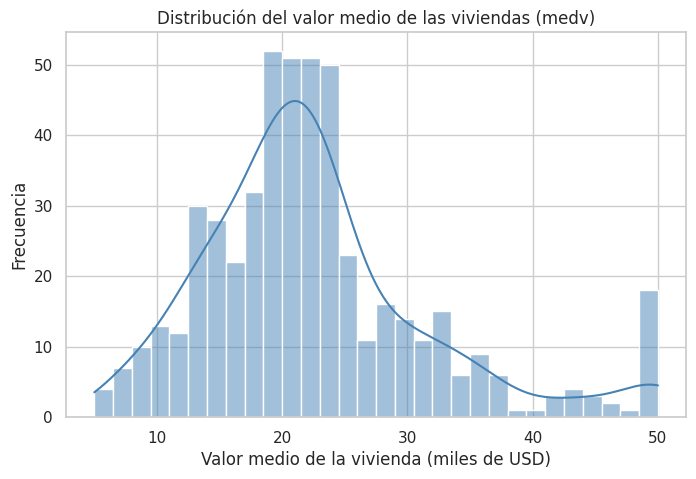

In [ ]:
# Visualización 1: Histograma de medv (distribución general)

plt.figure(figsize=(8, 5))
sns.histplot(df['medv'], kde=True, bins=30, color='steelblue')
plt.title('Distribución del valor medio de las viviendas (medv)')
plt.xlabel('Valor medio de la vivienda (miles de USD)')
plt.ylabel('Frecuencia')
plt.show()

/tmp/ipykernel_1927/2600999935.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='chas', y='medv', data=df, palette='Set2')


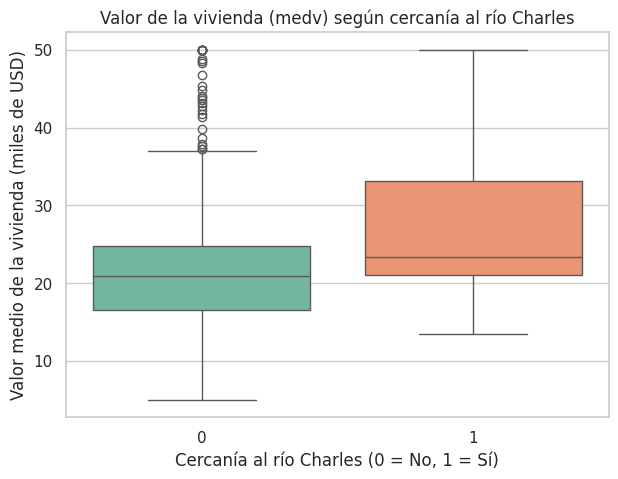

In [ ]:
# Visualización 2: Boxplot de medv por grupo (chas)

plt.figure(figsize=(7, 5))
sns.boxplot(x='chas', y='medv', data=df, palette='Set2')
plt.title('Valor de la vivienda (medv) según cercanía al río Charles')
plt.xlabel('Cercanía al río Charles (0 = No, 1 = Sí)')
plt.ylabel('Valor medio de la vivienda (miles de USD)')
plt.show()

## Paso 8 – Validación de supuestos

Antes de seleccionar la prueba inferencial es necesario validar dos supuestos: la normalidad de la variable dependiente en cada grupo y la homogeneidad de varianzas entre los grupos.

**A) Normalidad.** Se aplica la prueba de Shapiro-Wilk sobre `medv` en cada grupo por separado (no limita con el río / sí limita con el río), ya que la prueba de dos muestras que se use más adelante depende de si cada grupo se distribuye de forma aproximadamente normal. Si el p-value resulta menor a 0.05, se rechaza la normalidad para ese grupo; si es mayor o igual a 0.05, no se rechaza (con cautela).

**B) Homogeneidad de varianzas.** Se aplica la prueba de Levene para comparar la varianza de `medv` entre los dos grupos. Un p-value menor a 0.05 indica que las varianzas son significativamente distintas entre grupos (no se cumple la homogeneidad), lo cual, junto con el resultado de normalidad, determina si corresponde usar una prueba paramétrica clásica o una alternativa más robusta.

In [ ]:
# PASO 8 – Evaluación de supuestos

# A) Normalidad por grupo (Shapiro-Wilk)
grupo_0 = df[df['chas'] == 0]['medv']
grupo_1 = df[df['chas'] == 1]['medv']

shapiro_0 = stats.shapiro(grupo_0)
shapiro_1 = stats.shapiro(grupo_1)

print("Shapiro-Wilk - Grupo 0 (no limita con el río):")
print(f"  Estadístico = {shapiro_0.statistic:.4f}, p-value = {shapiro_0.pvalue:.4e}")

print("\nShapiro-Wilk - Grupo 1 (sí limita con el río):")
print(f"  Estadístico = {shapiro_1.statistic:.4f}, p-value = {shapiro_1.pvalue:.4e}")

# B) Homogeneidad de varianzas (Levene)
levene_test = stats.levene(grupo_0, grupo_1)
print("\nPrueba de Levene (homogeneidad de varianzas):")
print(f"  Estadístico = {levene_test.statistic:.4f}, p-value = {levene_test.pvalue:.4e}")

Shapiro-Wilk - Grupo 0 (no limita con el río):
  Estadístico = 0.9283, p-value = 3.1145e-14

Shapiro-Wilk - Grupo 1 (sí limita con el río):
  Estadístico = 0.8359, p-value = 1.1231e-04

Prueba de Levene (homogeneidad de varianzas):
  Estadístico = 4.5903, p-value = 3.2631e-02


## Paso 9 – Selección y justificación del análisis inferencial

Para elegir la prueba inferencial adecuada se tuvieron en cuenta cuatro criterios: el tipo de variables (una numérica continua y una categórica de 2 grupos), el resultado de la prueba de normalidad, el resultado de la prueba de homogeneidad de varianzas y el tamaño de los grupos.

Los resultados del Paso 8 mostraron que la variable `medv` **no cumple el supuesto de normalidad en ninguno de los dos grupos** (Shapiro-Wilk: p = 3.11e-14 para el grupo 0 y p = 1.12e-04 para el grupo 1, ambos menores a 0.05), y que **tampoco se cumple la homogeneidad de varianzas** (Levene: p = 0.0326, menor a 0.05). A esto se suma que los grupos están fuertemente desbalanceados (n1 = 471, n2 = 35), lo que hace que la prueba t de Student, pensada para grupos con distribución normal y varianzas similares, no sea la más adecuada en este caso.

Por lo anterior, se selecciona la **prueba U de Mann-Whitney**, que es la alternativa no paramétrica al t-test para dos muestras independientes: no exige normalidad y es más robusta frente a varianzas desiguales y tamaños de grupo distintos, ya que compara los rangos de los datos en lugar de sus medias directamente.


In [ ]:
# PASO 9 – Selección del análisis inferencial: prueba U de Mann-Whitney

resultado_mw = stats.mannwhitneyu(grupo_0, grupo_1, alternative='two-sided')

print("Prueba U de Mann-Whitney:")
print(f"Estadístico U = {resultado_mw.statistic:.4f}")
print(f"p-value = {resultado_mw.pvalue:.4e}")


Prueba U de Mann-Whitney:
Estadístico U = 5605.5000
p-value = 1.5817e-03


## Paso 10 – Resultados e interpretación

La prueba U de Mann-Whitney arrojó un estadístico U = 5605.50 y un p-value = 0.0016. Como este valor es menor al nivel de significancia de 0.05, existe evidencia estadística suficiente para **rechazar la hipótesis nula (H0)**.

Esto significa que sí existe una diferencia significativa en el valor promedio de las viviendas entre las zonas que limitan con el río Charles y las que no. En términos prácticos, y respaldado por lo observado en el boxplot y en las medias descriptivas del Paso 7, las zonas que limitan con el río Charles presentan valores de vivienda más altos (media ≈ 28.44) frente a las zonas que no limitan con él (media ≈ 22.09). Esto es consistente con la idea de que la cercanía al río actúa como un atributo que agrega valor a la propiedad, posiblemente asociado a la vista, la recreación o el prestigio de vivir cerca de esta zona.

Es importante aclarar que, al usar una prueba basada en rangos y no en medias, la conclusión formal es que las distribuciones de `medv` difieren entre los dos grupos, y no estrictamente que las medias sean diferentes; sin embargo, en este caso ambas lecturas apuntan en la misma dirección.


In [ ]:
# PASO 10 – Resultados e interpretación

alpha = 0.05
p_value = resultado_mw.pvalue

print(f"Estadístico U = {resultado_mw.statistic:.4f}")
print(f"p-value = {p_value:.4e}")
print(f"Nivel de significancia (alpha) = {alpha}")
print()

if p_value < alpha:
    print("Decisión: Se rechaza H0.")
    print("Conclusión: Existe evidencia de diferencia significativa en el valor de la vivienda")
    print("entre zonas que limitan con el río Charles y las que no.")
else:
    print("Decisión: No se rechaza H0.")
    print("Conclusión: No hay evidencia suficiente de diferencia entre los grupos.")


Estadístico U = 5605.5000
p-value = 1.5817e-03
Nivel de significancia (alpha) = 0.05

Decisión: Se rechaza H0.
Conclusión: Existe evidencia de diferencia significativa en el valor de la vivienda
entre zonas que limitan con el río Charles y las que no.


## Paso 11 – Conclusiones

**¿Qué aprendimos sobre los supuestos estadísticos?**

Este taller mostró que no siempre se pueden aplicar las pruebas estadísticas "clásicas" (como el t-test) sin antes verificar sus supuestos. En este caso, aunque el dataset tenía un tamaño de muestra considerable (n = 506), ni la normalidad ni la homogeneidad de varianzas se cumplieron, lo que llevó a usar una prueba no paramétrica (U de Mann-Whitney). Esto reforzó la idea de que la validación de supuestos no es un paso opcional, sino el que determina qué herramienta estadística es válida usar y qué tan confiables son las conclusiones que se obtienen.

**¿Qué limitaciones tuvo el dataset?**

La principal limitación fue el desbalance entre grupos (471 zonas que no limitan con el río frente a solo 35 que sí), lo cual reduce la robustez de las conclusiones para el grupo minoritario y puede hacer que el resultado sea sensible a unos pocos valores atípicos dentro de ese grupo. Además, el dataset contenía valores nulos en la variable `rm` que debieron imputarse, y al ser datos históricos de los años 70 sobre la ciudad de Boston, sus valores absolutos de vivienda no son comparables directamente con precios actuales.

**¿Qué análisis adicional se podría hacer con más datos?**

Con un dataset más grande y más balanceado entre grupos, se podría explorar si la diferencia en el valor de la vivienda por cercanía al río se mantiene al controlar por otras variables (como `crim`, `rm` o `lstat`) mediante un modelo de regresión múltiple, en lugar de comparar un solo par de variables de forma aislada. También sería interesante analizar la correlación entre `medv` y variables numéricas continuas como `rm` o `lstat`, para complementar la comparación de grupos con un análisis de relación entre variables numéricas.


In [ ]:
# Resumen final de referencia para las conclusiones

print("Resumen del análisis:")
print(f"- n total = {n_total}")
print(f"- Grupo 0 (no limita con el río): n1 = {tamano_grupos[0]}")
print(f"- Grupo 1 (sí limita con el río): n2 = {tamano_grupos[1]}")
print(f"- Prueba usada: U de Mann-Whitney (U = {resultado_mw.statistic:.4f}, p = {resultado_mw.pvalue:.4e})")
print(f"- Decisión: Se rechaza H0")


Resumen del análisis:
- n total = 506
- Grupo 0 (no limita con el río): n1 = 471
- Grupo 1 (sí limita con el río): n2 = 35
- Prueba usada: U de Mann-Whitney (U = 5605.5000, p = 1.5817e-03)
- Decisión: Se rechaza H0


## Referencias bibliográficas

Boschetti, A., & Massaron, L. (2018). *Python data science essentials: A practitioner's guide covering essential data science principles, tools, and techniques*. Packt Publishing Ltd.

Cady, F. (2020). *Data science: The executive summary - a technical book for non-technical professionals*. John Wiley & Sons, Incorporated.

Harrison, D., & Rubinfeld, D. L. (1978). Hedonic housing prices and the demand for clean air. *Journal of Environmental Economics and Management*, *5*(1), 81–102. https://doi.org/10.1016/0095-0696(78)90006-2

arunjangir245. (s.f.). *Boston Housing Dataset* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/arunjangir245/boston-housing-dataset

McKnight, P. E., & Najab, J. (2010). Mann-Whitney U test. En *The Corsini encyclopedia of psychology*. John Wiley & Sons. https://doi.org/10.1002/9780470479216.corpsy0524

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, *17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2